δ = 0.01: |ρ₁| ≤ 0.201990, |ρ₂| ≤ 0.285657
δ = 0.001: |ρ₁| ≤ 0.063309, |ρ₂| ≤ 0.089532
δ = 0.0001: |ρ₁| ≤ 0.020002, |ρ₂| ≤ 0.028287


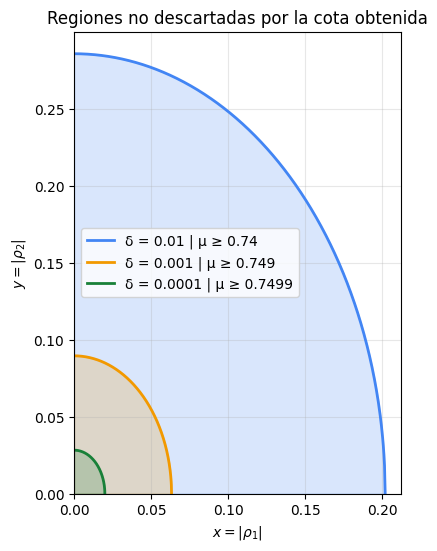

In [ ]:
#1. Comprobamos que el valor del margen "delta" define la región de valores que tendrán los parámetros de orden
import numpy as np
import matplotlib.pyplot as plt

margenes = [0.01, 0.001, 0.0001]
colores = ["#4285F4", "#F29900", "#188038"]

fig, ax = plt.subplots(figsize=(8, 6))

for delta, color in zip(margenes, colores):
    cota = 8 * delta + 16 * delta**2

    # Máximos individuales permitidos por la desigualdad
    x_max = np.sqrt(cota / 2)
    y_max = np.sqrt(cota)

    # Frontera: y = sqrt(cota - 2*x²)
    x = np.linspace(0, x_max, 500)
    y = np.sqrt(np.maximum(cota - 2 * x**2, 0))

    ax.fill_between(x, 0, y, color=color, alpha=0.20)
    ax.plot(
        x, y,
        color=color,
        linewidth=2,
        label=f"δ = {delta:g} | μ ≥ {0.75 - delta:g}"
    )

    print(
        f"δ = {delta:g}: "
        f"|ρ₁| ≤ {x_max:.6f}, "
        f"|ρ₂| ≤ {y_max:.6f}"
    )

ax.set_xlabel(r"$x = |\rho_1|$")
ax.set_ylabel(r"$y = |\rho_2|$")
ax.set_title("Regiones no descartadas por la cota obtenida")
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)
ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

In [ ]:
#2. Ahora bien, ¿qué pasa si queremos que los parámetros de orden tengan ciertos valores que a su vez, respeten una tolerancia "epsilon"? ¿Podemos usar "delta"?
import numpy as np

def margen_suficiente(epsilon):
    if epsilon <= 0:
        raise ValueError("La tolerancia debe ser positiva.")

    margen = epsilon**2 / (
        4 * (np.sqrt(1 + epsilon**2) + 1)
    )
    return min(1 / 32, margen)

for epsilon in [0.2, 0.1, 0.05, 0.01]:
    delta = margen_suficiente(epsilon)

    print(
        f"Tolerancia ε = {epsilon:.3f} | "
        f"Margen δ = {delta:.8f} | "
        f"Conectividad exigida μ ≥ {0.75 - delta:.8f}"
    )

Tolerancia ε = 0.200 | Margen δ = 0.00495098 | Conectividad exigida μ ≥ 0.74504902
Tolerancia ε = 0.100 | Margen δ = 0.00124689 | Conectividad exigida μ ≥ 0.74875311
Tolerancia ε = 0.050 | Margen δ = 0.00031230 | Conectividad exigida μ ≥ 0.74968770
Tolerancia ε = 0.010 | Margen δ = 0.00001250 | Conectividad exigida μ ≥ 0.74998750


In [ ]:
#3. ¿El margen delta está implicado en la proporción de nodos no conectados que están lejos de ser opuestos?
import numpy as np

h = np.deg2rad(1)
a = np.deg2rad(15)
objetivo = 0.05

print("δ          s          Cota N_a/n     ¿Garantiza el objetivo?")

for delta in [1e-6, 1e-8, 1e-10, 1e-12]:
    epsilon = np.sqrt(8 * delta + 16 * delta**2)

    s = np.sqrt(
        (3 * delta + 4 * delta**2)
        * (1 + 2 / (1 - np.cos(h)))
    )

    cota = (
        epsilon + 4 * s + 8 * h**2
    ) / (1 - np.cos(2 * a))

    hipotesis = (
        0 < delta <= 1 / 32
        and s < 1 / 8
        and 3 * h < np.pi
    )

    garantiza = hipotesis and cota <= objetivo

    print(
        f"{delta:.0e}     "
        f"{s:.6f}     "
        f"{cota:.6f}       "
        f"{'Sí' if garantiza else 'No'}"
    )

δ          s          Cota N_a/n     ¿Garantiza el objetivo?
1e-06     0.198489     5.965458       No
1e-08     0.019849     0.612916       No
1e-10     0.001985     0.077662       No
1e-12     0.000198     0.024137       Sí
